1. Data Loading & Understanding

Check the header of the CSV file

In [62]:
import pandas as pd

df = pd.read_csv('/Users/hongmo/Desktop/Gradient Boosting/data/application_train.csv')
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Check the data type of each column

In [63]:
df.dtypes

SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE                str
CODE_GENDER                       str
FLAG_OWN_CAR                      str
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

Identify numerical and categorical variables

In [64]:
# numerical columns
numerical = df.select_dtypes(include = ['int64', 'float64']).columns

# categorial columns
categorical = df.select_dtypes(include = ['object', 'category', 'str']).columns

print("numerical", numerical.tolist())
print("categorical", categorical.tolist())

numerical ['SK_ID_CURR', 'TARGET', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MO

Exploratory Data Analysis

In [65]:
# analysis the distribution  of the target, and identify class imbalance

df['TARGET'].value_counts() # statistics of the target variable

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [66]:
target_percentage = df['TARGET'].value_counts(normalize=True) * 100
print("Percentage of each class in the target variable:")
print(target_percentage)

percentage_zero = target_percentage[0]
percentage_one = target_percentage[1]
print(f"Percentage of class 0: {percentage_zero:.2f}%")
print(f"Percentage of class 1: {percentage_one:.2f}%")

Percentage of each class in the target variable:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64
Percentage of class 0: 91.93%
Percentage of class 1: 8.07%


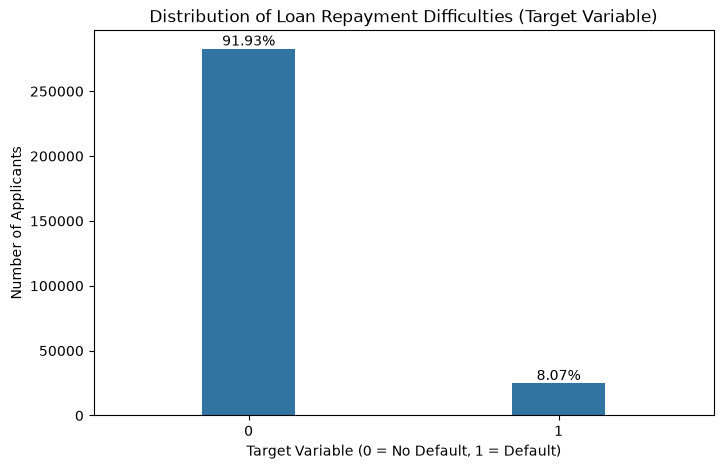

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of the target variable
plt.figure(figsize=(8, 5))
plt.title('Distribution of Loan Repayment Difficulties (Target Variable)')

ax = sns.countplot(x='TARGET', data=df, width=0.3)

# label the percentage on top of each bar
for p in ax.patches:
    height = p.get_height()
    percentage = height / len(df) * 100
    ax.annotate(f'{percentage:.2f}%', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, color='black')

plt.xlabel('Target Variable (0 = No Default, 1 = Default)')
plt.ylabel('Number of Applicants')
plt.show()

In [68]:
# identify class imbalance

imbalance_ratio = percentage_zero / percentage_one
print(f"Imbalance ratio (class 0 : class 1) = {imbalance_ratio:.2f} : 1.00")



Imbalance ratio (class 0 : class 1) = 11.39 : 1.00


Examine missing values and their proportions

In [69]:
# Count the number of missing values in each column
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values[missing_values > 0])

missing_percentage = df.isnull().mean() * 100
print("\nPercentage of missing values in each column:")
print(missing_percentage[missing_percentage > 0])

Missing values in each column:
AMT_ANNUITY                       12
AMT_GOODS_PRICE                  278
NAME_TYPE_SUITE                 1292
OWN_CAR_AGE                   202929
OCCUPATION_TYPE                96391
                               ...  
AMT_REQ_CREDIT_BUREAU_DAY      41519
AMT_REQ_CREDIT_BUREAU_WEEK     41519
AMT_REQ_CREDIT_BUREAU_MON      41519
AMT_REQ_CREDIT_BUREAU_QRT      41519
AMT_REQ_CREDIT_BUREAU_YEAR     41519
Length: 67, dtype: int64

Percentage of missing values in each column:
AMT_ANNUITY                    0.003902
AMT_GOODS_PRICE                0.090403
NAME_TYPE_SUITE                0.420148
OWN_CAR_AGE                   65.990810
OCCUPATION_TYPE               31.345545
                                ...    
AMT_REQ_CREDIT_BUREAU_DAY     13.501631
AMT_REQ_CREDIT_BUREAU_WEEK    13.501631
AMT_REQ_CREDIT_BUREAU_MON     13.501631
AMT_REQ_CREDIT_BUREAU_QRT     13.501631
AMT_REQ_CREDIT_BUREAU_YEAR    13.501631
Length: 67, dtype: float64


In [70]:
missing_summary = pd.DataFrame({
    'Missing Values': missing_values, 
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Display the top 10 columns with the most missing values
display(missing_summary.head(20))  

,Missing Values,Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


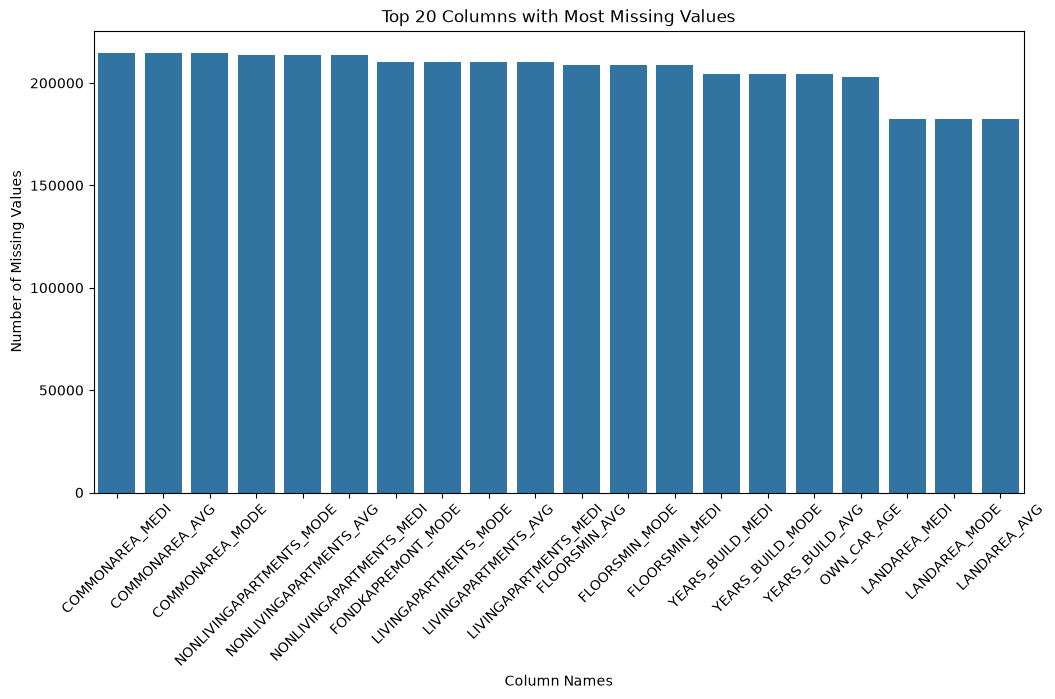

In [71]:
top_missing_columns = missing_summary.head(20)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_missing_columns.index, y=top_missing_columns['Missing Values'])
plt.title('Top 20 Columns with Most Missing Values')
plt.xticks(rotation=45)
plt.xlabel('Column Names')
plt.ylabel('Number of Missing Values')
plt.show()

Explore numerical and categorical feature distributions

In [72]:
eda_numerical_features = [col for col in df.columns if df[col].dtype in ['int64', 'float64']]
df[eda_numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


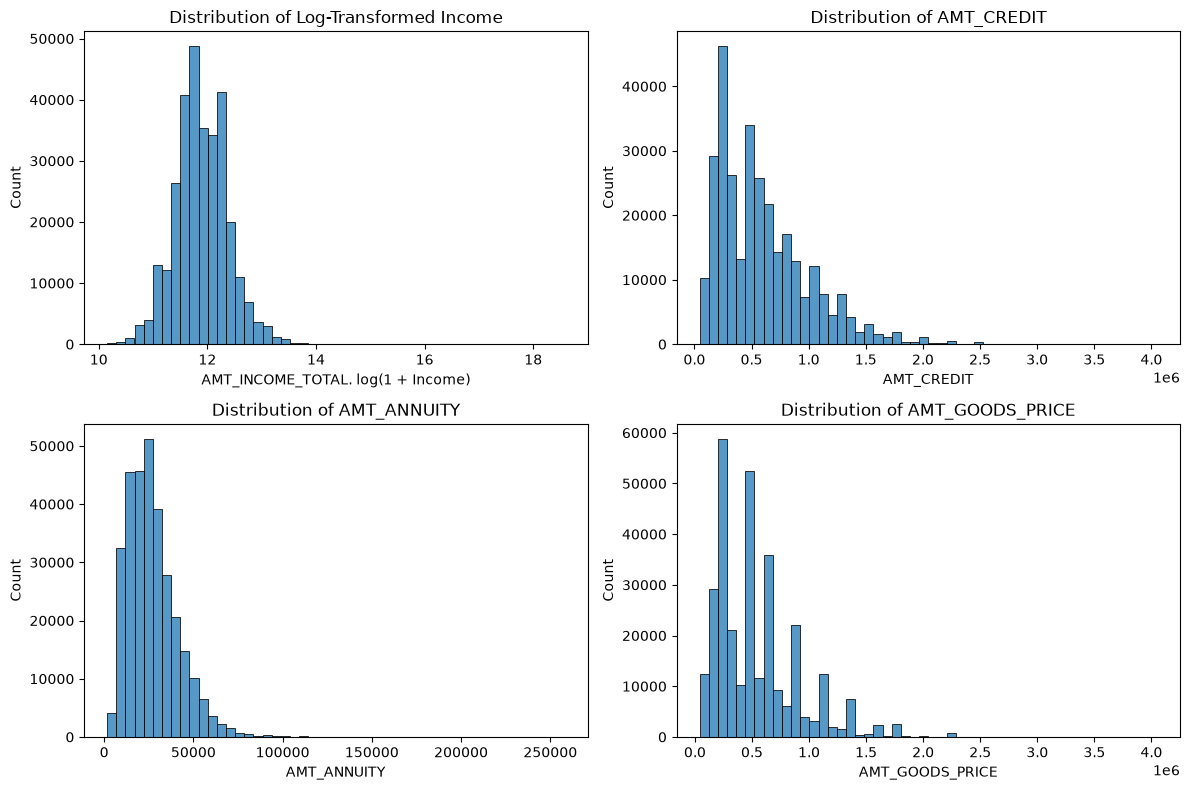

In [73]:
import numpy as np

features = ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# First plot: log-transformed income
sns.histplot(
    np.log1p(df['AMT_INCOME_TOTAL']),
    bins=50,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Distribution of Log-Transformed Income")
axes[0, 0].set_xlabel("AMT_INCOME_TOTAL. log(1 + Income)")

# Remaining three plots
for ax, feature in zip(axes.flatten()[1:], features):
    sns.histplot(
        data=df,
        x=feature,
        bins=50,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

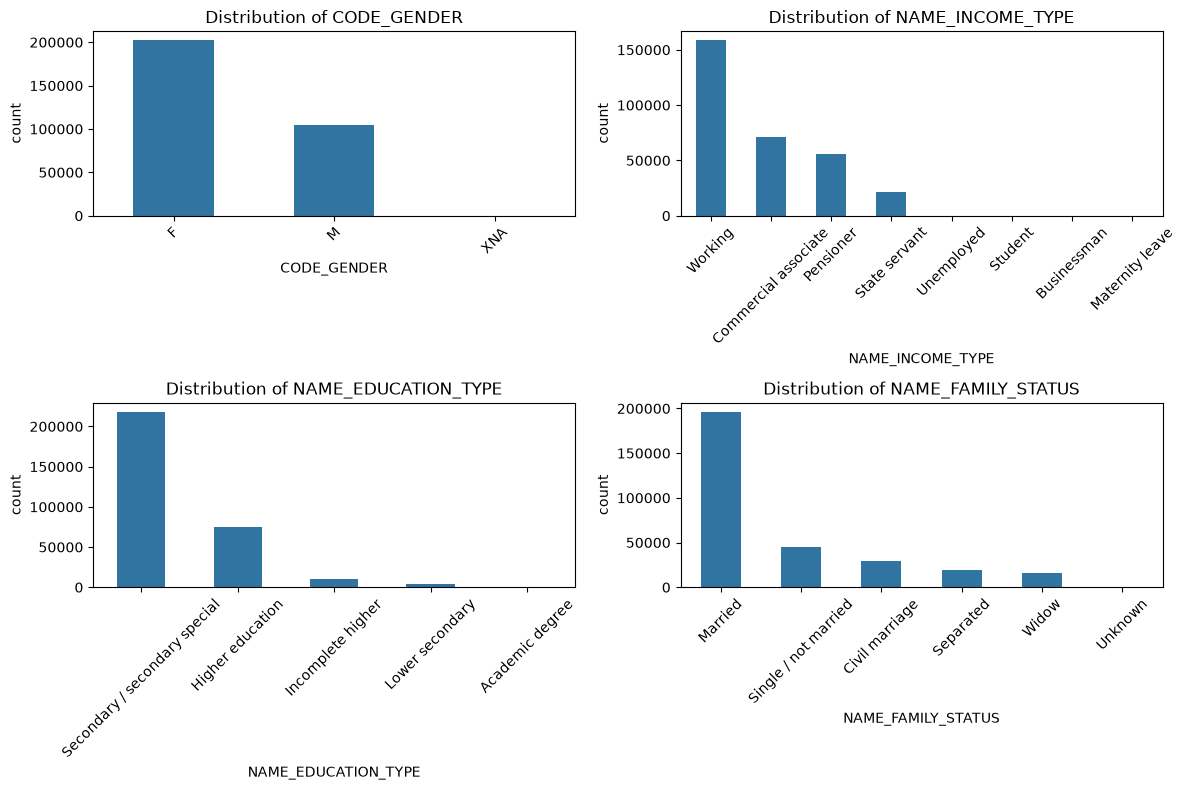

In [74]:
# Select categorical features
features = [
    'CODE_GENDER',
    'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS'
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), features):
    sns.countplot(
        data=df,
        x=feature,
        ax=ax,
        order=df[feature].value_counts().index,
        width = 0.5
    )

    ax.set_title(f"Distribution of {feature}")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


feature target relationship analysis -- AMT_CREDIT

In [75]:
credit_group = pd.qcut(
    df["AMT_CREDIT"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

credit_default_rate = (
    df.groupby(credit_group, observed=True)["TARGET"].mean() * 100
)

display(credit_default_rate)

AMT_CREDIT
Low          7.242958
Medium       9.683407
High         9.161032
Very High    6.214086
Name: TARGET, dtype: float64

Generate Correlation Heatmap

In [76]:
selected_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CNT_CHILDREN",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "TARGET"
]

correlation_matrix = df[selected_features].corr()
display(correlation_matrix.round(2))

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,CNT_CHILDREN,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,TARGET
AMT_INCOME_TOTAL,1.00,0.16,0.19,0.16,0.03,-0.06,0.01,0.03,0.06,-0.03,-0.00
AMT_CREDIT,0.16,1.00,0.77,0.99,-0.06,-0.07,0.00,0.17,0.13,0.04,-0.03
AMT_ANNUITY,0.19,0.77,1.00,0.78,0.01,-0.10,0.02,0.12,0.13,0.03,-0.01
AMT_GOODS_PRICE,0.16,0.99,0.78,1.00,-0.05,-0.06,-0.00,0.18,0.14,0.05,-0.04
DAYS_BIRTH,0.03,-0.06,0.01,-0.05,1.00,-0.62,0.33,-0.60,-0.09,-0.21,0.08
DAYS_EMPLOYED,-0.06,-0.07,-0.10,-0.06,-0.62,1.00,-0.24,0.29,-0.02,0.11,-0.04
CNT_CHILDREN,0.01,0.00,0.02,-0.00,0.33,-0.24,1.00,-0.14,-0.02,-0.04,0.02
EXT_SOURCE_1,0.03,0.17,0.12,0.18,-0.60,0.29,-0.14,1.00,0.21,0.19,-0.16
EXT_SOURCE_2,0.06,0.13,0.13,0.14,-0.09,-0.02,-0.02,0.21,1.00,0.11,-0.16
EXT_SOURCE_3,-0.03,0.04,0.03,0.05,-0.21,0.11,-0.04,0.19,0.11,1.00,-0.18


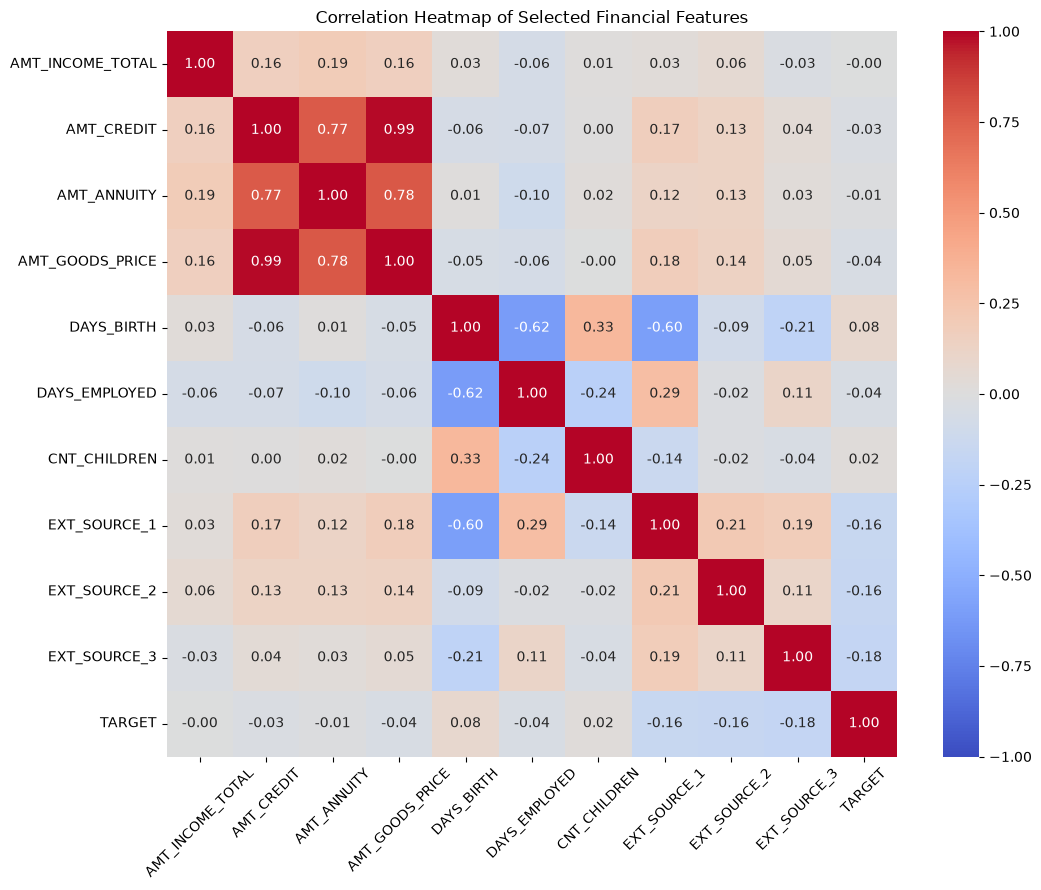

In [77]:
plt.figure(figsize=(11, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Selected Financial Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [78]:
target_correlation = (
    correlation_matrix["TARGET"]
    .drop("TARGET")
    .sort_values(key=abs, ascending=False)
)

display(target_correlation)

EXT_SOURCE_3       -0.178919
EXT_SOURCE_2       -0.160472
EXT_SOURCE_1       -0.155317
DAYS_BIRTH          0.078239
DAYS_EMPLOYED      -0.044932
AMT_GOODS_PRICE    -0.039645
AMT_CREDIT         -0.030369
CNT_CHILDREN        0.019187
AMT_ANNUITY        -0.012817
AMT_INCOME_TOTAL   -0.003982
Name: TARGET, dtype: float64

Imputation

In [79]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["TARGET", "SK_ID_CURR"])
y = df["TARGET"]

# First split: 60% train, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

# Second split: 20% validation, 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [80]:
# Identify feature types
numerical_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 104
Categorical features: 16


remove identifiers and investigate potential data leakage

In [81]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline([("imputer", SimpleImputer(strategy="median"))])

# Categorical preprocessing
categorical_transformer = Pipeline([("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])